# 03 · Análisis Detallado — Entrevistas al Mercado Automotor

**Notebook de apoyo (Fase 5 - EDA)**

Este notebook analiza las 30 entrevistas realizadas a personas sobre la compra y venta de automóviles en La Habana.

| Dataset | Registros | Archivo |
|---|---|---|
| Entrevistas | 30 personas | `data/processed_final/entrevistas_final.json` |

## 1. Librerías y configuración

In [1]:
import json
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 6)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 140)

FIG_DIR = Path("reports") / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

BASE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = BASE / "data" / "processed_final"

def cargar_json(ruta):
    with open(ruta, encoding="utf-8") as archivo:
        return json.load(archivo)

entrevistas = cargar_json(DATA / "entrevistas_final.json")
df = pd.DataFrame(entrevistas)

print("Entrevistas cargadas:", len(df))
print("Columnas:", list(df.columns))

Entrevistas cargadas: 30
Columnas: ['id_entrevista', 'zona', 'ocupacion', 'relacion_con_el_mercado', 'propietario_vehiculo', 'experiencia_vehiculos_electricos', 'respuestas']


## 2. Análisis demográfico

=== DISTRIBUCIÓN POR ZONA ===
zona
Alamar           20
Vedado            3
Guanabacoa        3
Playa             2
Cerro             1
Centro Habana     1


C:\Users\jorge\AppData\Local\Temp\ipykernel_24180\1283555980.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=zona_counts.index, y=zona_counts.values, ax=ax, palette="viridis")


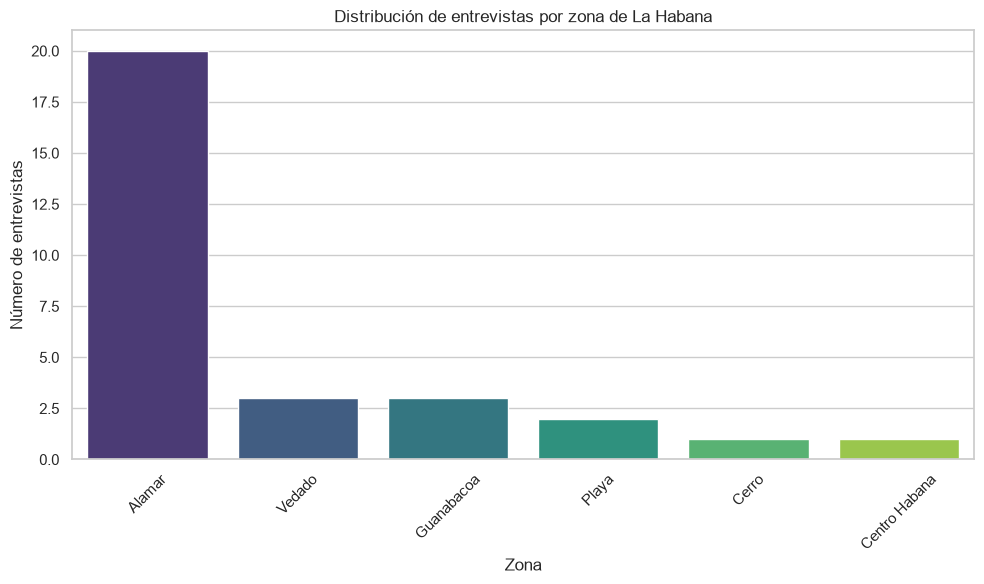

In [2]:
print("=== DISTRIBUCIÓN POR ZONA ===")
print(df["zona"].value_counts().to_string())

fig, ax = plt.subplots(figsize=(10, 6))
zona_counts = df["zona"].value_counts()
sns.barplot(x=zona_counts.index, y=zona_counts.values, ax=ax, palette="viridis")
ax.set_title("Distribución de entrevistas por zona de La Habana")
ax.set_xlabel("Zona")
ax.set_ylabel("Número de entrevistas")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(FIG_DIR / "f11_zona_entrevistas.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Análisis de percepciones

=== OPINIÓN SOBRE VEHÍCULOS ELÉCTRICOS ===
{'Mala': 26, 'Buena': 2, 'Indiferente': 2}


C:\Users\jorge\AppData\Local\Temp\ipykernel_24180\2220625859.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(op_counts.keys()), y=list(op_counts.values()), ax=ax, palette="Set2")


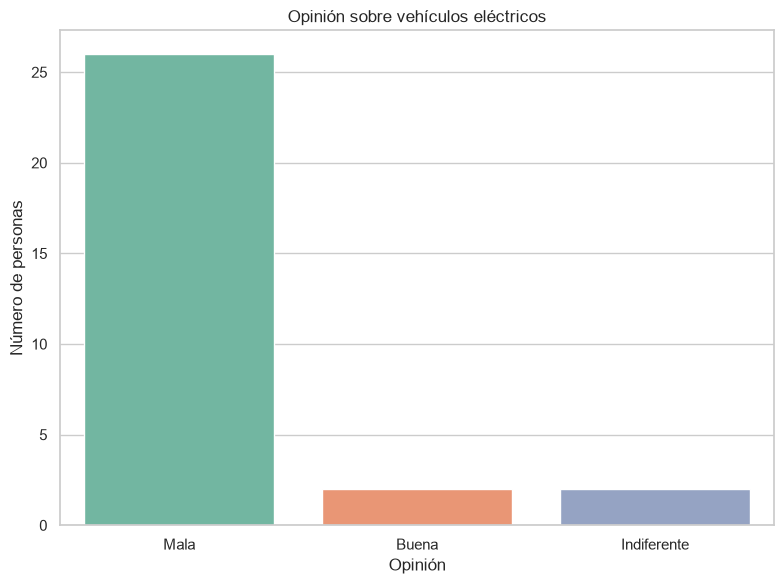

In [3]:
print("=== OPINIÓN SOBRE VEHÍCULOS ELÉCTRICOS ===")
opiniones = []
for r in entrevistas:
    if r.get('respuestas') and r['respuestas'].get('opinion_vehiculos_electricos'):
        opiniones.append(r['respuestas']['opinion_vehiculos_electricos'])
print(str(dict(Counter(opiniones))))

fig, ax = plt.subplots(figsize=(8, 6))
op_counts = Counter(opiniones)
sns.barplot(x=list(op_counts.keys()), y=list(op_counts.values()), ax=ax, palette="Set2")
ax.set_title("Opinión sobre vehículos eléctricos")
ax.set_xlabel("Opinión")
ax.set_ylabel("Número de personas")
plt.tight_layout()
plt.savefig(FIG_DIR / "f11_opinion_electricos.png", dpi=150, bbox_inches="tight")
plt.show()


=== PREDOMINIO DE AUTOS CLÁSICOS ===
{True: 25, False: 5}

=== TIPO DE VEHÍCULO OBSERVADO ===
{'Clásicos': 21, 'Modernos': 9}


C:\Users\jorge\AppData\Local\Temp\ipykernel_24180\3133753102.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(tipo_counts.keys()), y=list(tipo_counts.values()), ax=ax, palette="rocket")


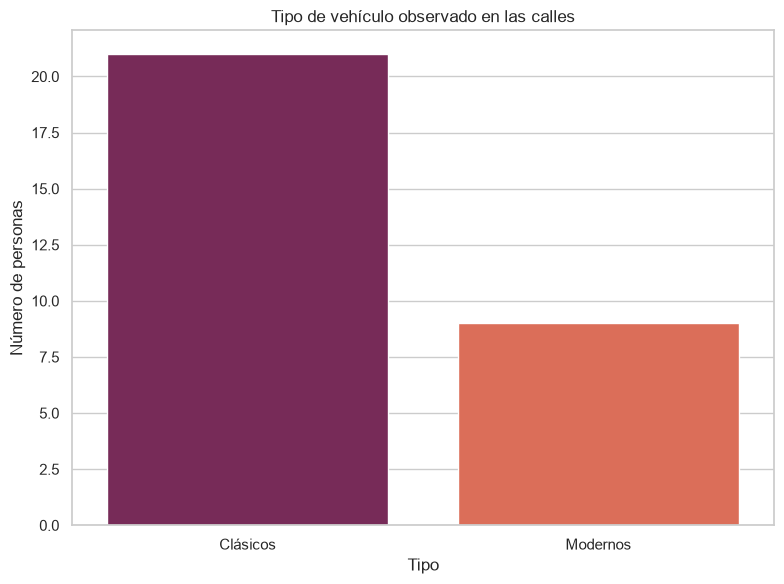

In [4]:
print("\n=== PREDOMINIO DE AUTOS CLÁSICOS ===")
clasicos = []
for r in entrevistas:
    if r.get('respuestas') and 'predominio_autos_clasicos' in r['respuestas']:
        clasicos.append(r['respuestas']['predominio_autos_clasicos'])
print(str(dict(Counter(clasicos))))

print("\n=== TIPO DE VEHÍCULO OBSERVADO ===")
tipo_obs = []
for r in entrevistas:
    if r.get('respuestas') and r['respuestas'].get('tipo_vehiculo_observado'):
        tipo_obs.append(r['respuestas']['tipo_vehiculo_observado'])
print(str(dict(Counter(tipo_obs))))

fig, ax = plt.subplots(figsize=(8, 6))
tipo_counts = Counter(tipo_obs)
sns.barplot(x=list(tipo_counts.keys()), y=list(tipo_counts.values()), ax=ax, palette="rocket")
ax.set_title("Tipo de vehículo observado en las calles")
ax.set_xlabel("Tipo")
ax.set_ylabel("Número de personas")
plt.tight_layout()
plt.savefig(FIG_DIR / "f13_tipo_vehiculo_observado.png", dpi=150, bbox_inches="tight")
plt.show()


=== MARCAS MODERNAS MÁS MENCIONADAS ===
Kia: 28
Hyundai: 25
Foton: 14
Bestune: 11
Mercedes: 5
DFSK: 3
Geely: 2
BMW: 1
Toyota: 1


C:\Users\jorge\AppData\Local\Temp\ipykernel_24180\1667433271.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=[m[0] for m in top_marcas], y=[m[1] for m in top_marcas], ax=ax, palette="mako")


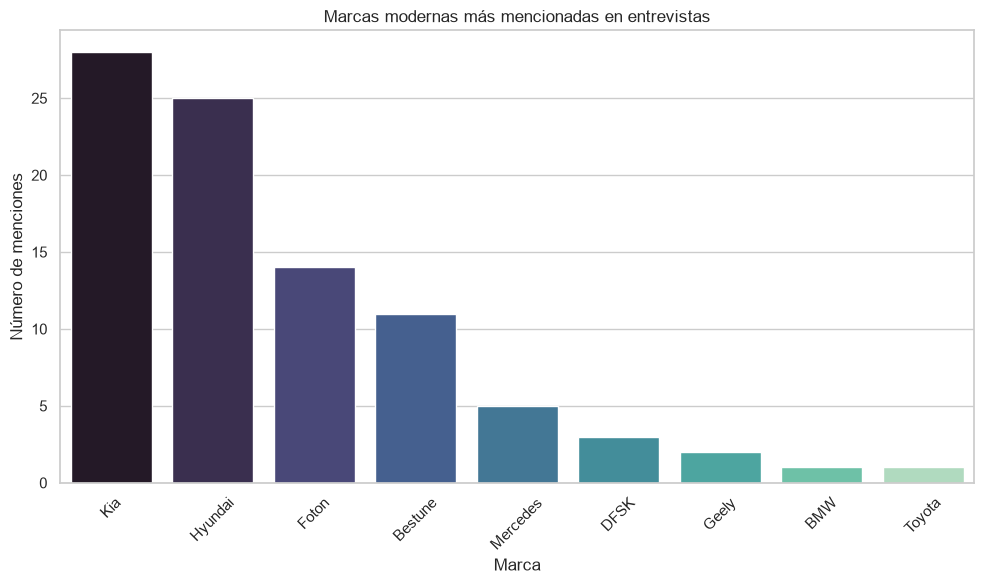

In [5]:
print("\n=== MARCAS MODERNAS MÁS MENCIONADAS ===")
todas_marcas = []
for r in entrevistas:
    if r.get('respuestas') and r['respuestas'].get('marcas_modernas_observadas'):
        todas_marcas.extend(r['respuestas']['marcas_modernas_observadas'])
marcas_cont = Counter(todas_marcas)
for marca, cnt in marcas_cont.most_common(20):
    print(marca + ': ' + str(cnt))

fig, ax = plt.subplots(figsize=(10, 6))
top_marcas = marcas_cont.most_common(10)
sns.barplot(x=[m[0] for m in top_marcas], y=[m[1] for m in top_marcas], ax=ax, palette="mako")
ax.set_title("Marcas modernas más mencionadas en entrevistas")
ax.set_xlabel("Marca")
ax.set_ylabel("Número de menciones")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(FIG_DIR / "f13_marcas_mencionadas.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Cruces de variables

In [6]:
print("=== OPINIÓN SOBRE ELÉCTRICOS POR ZONA ===")
for zona in sorted(df["zona"].unique()):
    sub = df[df["zona"] == zona]
    ops = []
    for r in sub.to_dict('records'):
        if r.get('respuestas') and r['respuestas'].get('opinion_vehiculos_electricos'):
            ops.append(r['respuestas']['opinion_vehiculos_electricos'])
    print(zona + ': ' + str(dict(Counter(ops))))

print("\n=== PREDOMINIO DE CLÁSICOS POR ZONA ===")
for zona in sorted(df["zona"].unique()):
    sub = df[df["zona"] == zona]
    cls = []
    for r in sub.to_dict('records'):
        if r.get('respuestas') and 'predominio_autos_clasicos' in r['respuestas']:
            cls.append(str(r['respuestas']['predominio_autos_clasicos']))
    print(zona + ': ' + str(dict(Counter(cls))))

=== OPINIÓN SOBRE ELÉCTRICOS POR ZONA ===
Alamar: {'Mala': 17, 'Buena': 2, 'Indiferente': 1}
Centro Habana: {'Mala': 1}
Cerro: {'Mala': 1}
Guanabacoa: {'Mala': 3}
Playa: {'Indiferente': 1, 'Mala': 1}
Vedado: {'Mala': 3}

=== PREDOMINIO DE CLÁSICOS POR ZONA ===
Alamar: {'True': 20}
Centro Habana: {'True': 1}
Cerro: {'True': 1}
Guanabacoa: {'True': 3}
Playa: {'False': 2}
Vedado: {'False': 3}


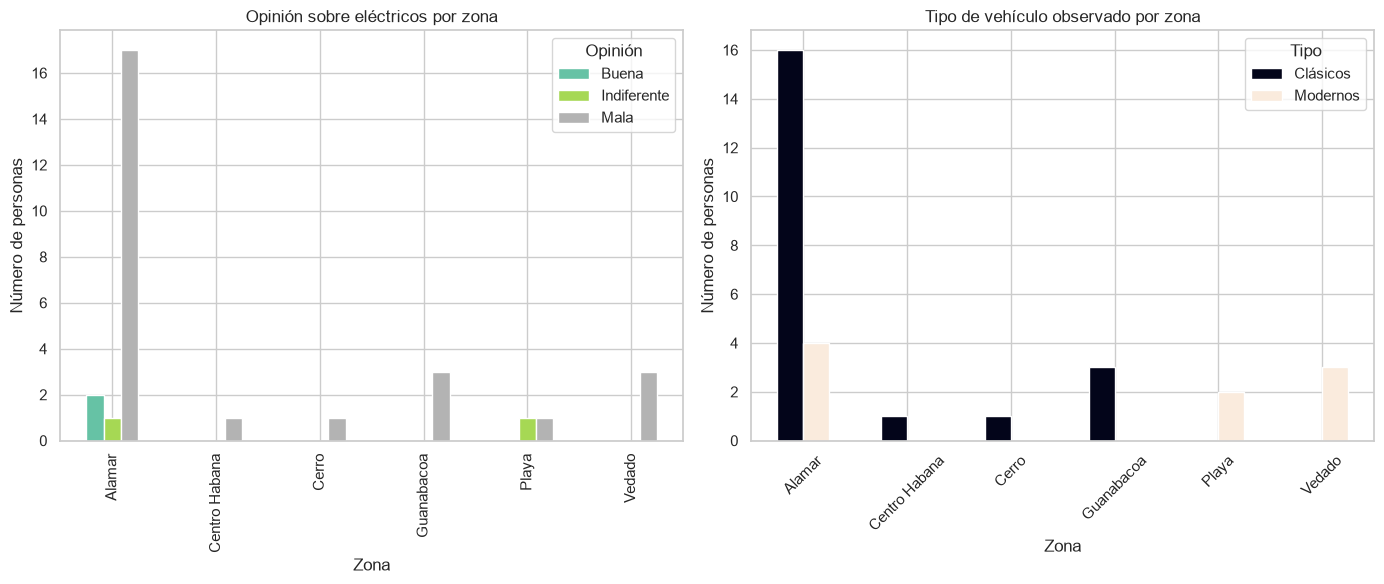

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Opinión EV por zona
zona_op = []
for r in entrevistas:
    if r.get('respuestas') and r['respuestas'].get('opinion_vehiculos_electricos'):
        zona_op.append({'zona': r['zona'], 'opinion': r['respuestas']['opinion_vehiculos_electricos']})
df_zona_op = pd.DataFrame(zona_op)

if not df_zona_op.empty:
    pd.crosstab(df_zona_op['zona'], df_zona_op['opinion']).plot(kind='bar', ax=axes[0], colormap='Set2')
    axes[0].set_title("Opinión sobre eléctricos por zona")
    axes[0].set_xlabel("Zona")
    axes[0].set_ylabel("Número de personas")
    axes[0].legend(title='Opinión')
    plt.xticks(rotation=45)

# Tipo observado por zona
zona_tipo = []
for r in entrevistas:
    if r.get('respuestas') and r['respuestas'].get('tipo_vehiculo_observado'):
        zona_tipo.append({'zona': r['zona'], 'tipo': r['respuestas']['tipo_vehiculo_observado']})
df_zona_tipo = pd.DataFrame(zona_tipo)

if not df_zona_tipo.empty:
    pd.crosstab(df_zona_tipo['zona'], df_zona_tipo['tipo']).plot(kind='bar', ax=axes[1], colormap='rocket')
    axes[1].set_title("Tipo de vehículo observado por zona")
    axes[1].set_xlabel("Zona")
    axes[1].set_ylabel("Número de personas")
    axes[1].legend(title='Tipo')
    plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig(FIG_DIR / "f12_percepcion_por_zona.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
print("\n=== PROPIETARIOS vs NO PROPIETARIOS ===")
prop = Counter()
for r in entrevistas:
    pv = r.get('propietario_vehiculo', '')
    if 'Sí' in str(pv):
        prop['Propietario'] += 1
    else:
        prop['No propietario'] += 1
print(dict(prop))

print("\n=== OCUPACIÓN ===")
print(df["ocupacion"].value_counts().to_string())


=== PROPIETARIOS vs NO PROPIETARIOS ===
{'Propietario': 9, 'No propietario': 21}

=== OCUPACIÓN ===
ocupacion
Mecánico independiente             1
Cuentapropia                       1
Taxista particular                 1
Joven profesional (informático)    1
Mipyme (mensajería)                1
Jubilado                           1
Militar (chofer)                   1
Estudiante universitario           1
Costurera (trabajadora privada)    1
Electricista                       1
Trabajador del MINEM               1
Enfermera                          1
Mecánico de taller estatal         1
Pensionista                        1
Trabajador de Turismo              1
Profesora                          1
Albañil                            1
Comerciante de alimentos           1
Ama de casa (joven)                1
Mipyme (taller privado)            1
Taxista de moto eléctrica          1
Mipyme (importación)               1
Profesional de la salud            1
Mipyme (restaurante)               1
A

## 5. Conclusiones de las entrevistas

- **25 de 30 personas (83%) creen que predominan los autos clásicos** en las calles de La Habana.
- **26 de 30 personas (87%) tienen una opinión 'Mala' sobre vehículos eléctricos**, solo 2 opinan 'Buena'.
- **Kia y Hyundai** son las marcas modernas más mencionadas (28 y 25 menciones respectivamente).
- **21 personas observan principalmente clásicos** en las calles, solo 9 observan modernos.
- En Alamar (zona con más entrevistas, 20), 20 de 20 creen que predominan los clásicos y 17 opinan 'Mala' sobre eléctricos.
- En Vedado y Playa hay más apertura (0 personas creen que predominan los clásicos en esas zonas), pero persisten dudas por la infraestructura de carga.
- El escepticismo hacia los eléctricos se relaciona con los apagones y la escasez de electricidad estable.